In [1]:
import numpy
import pandas
import os
import json
import matplotlib.pyplot as plt

In [2]:
# First lets take a quick look at the scores of the all the JSON models (so we can tell which should be removed as misfolded structures)
json_dir = "../dat/"
dirs = os.listdir(json_dir)
jsons = []
json_scores = []
for d in dirs:
    json_file = os.path.join(json_dir, d, f"{d}.json")
    if not os.path.exists(json_file):
        continue
    with open(json_file, "r") as f:
        data = json.load(f)
    score = {"name": d}
    score.update(data.get("Scoring", {}))
    # json_scores.append({"file": json_file, "scoring": score})
    json_scores.append(score)
    jsons.append(data)

# Convert to DataFrame for easier analysis
json_scores_df = pandas.DataFrame(json_scores)
# json_scores_df.sort_values(by="score", ascending=False, inplace=True)
json_scores_df.reset_index(drop=True, inplace=True)
json_scores_df




,name,Sequence,Consensus,Secondary,Region,Components,pLDDT,Final
0,1ao7,1.0,1.000000,1.000000,1.000000,1.000000,1.0,1.000000
1,1bd2,1.0,1.000000,1.000000,1.000000,1.000000,1.0,1.000000
2,1d9k,1.0,1.000000,0.888889,1.000000,1.000000,1.0,0.981481
3,1fo0,1.0,0.444444,0.888889,0.636364,1.000000,1.0,0.828283
4,1fyt,1.0,1.000000,0.888889,1.000000,1.000000,1.0,0.981481
...,...,...,...,...,...,...,...,...
2480,Test_995,1.0,0.944444,1.000000,1.000000,0.666667,1.0,0.935185
2481,Test_996,1.0,1.000000,1.000000,1.000000,0.666667,1.0,0.944444
2482,Test_997,1.0,1.000000,1.000000,1.000000,0.666667,1.0,0.944444
2483,Test_998,1.0,1.000000,1.000000,1.000000,0.666667,1.0,0.944444


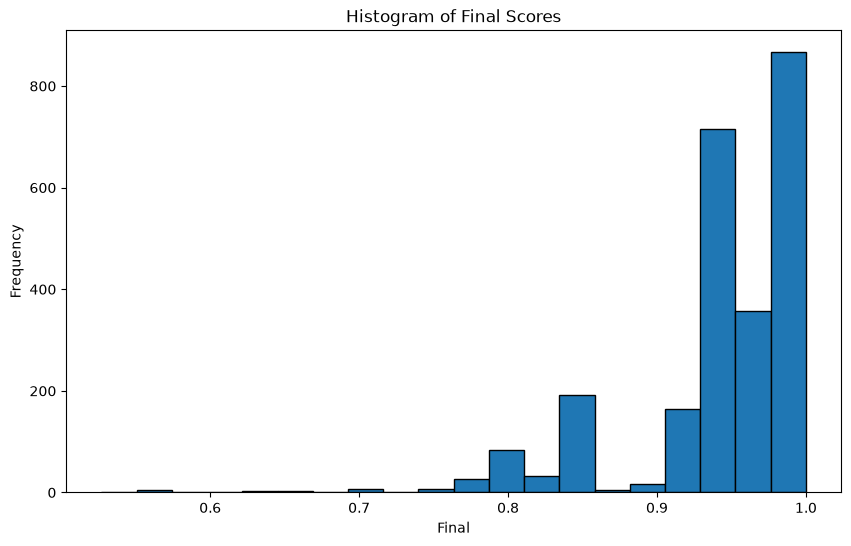

In [3]:
#Plot the histogram for the "Final" column
plt.figure(figsize=(10, 6))
plt.hist(json_scores_df["Final"].dropna(), bins=20, edgecolor="k")
plt.xlabel("Final")
plt.ylabel("Frequency")
plt.title("Histogram of Final Scores")
plt.show()

#plot the histogram for the sum of all columns (except name and "Secondary")
# json_scores_sum = json_scores_df.drop(columns=["name", "Secondary"], errors="ignore").sum(axis=1)
# plt.figure(figsize=(10, 6))
# plt.hist(json_scores_sum.dropna(), bins=20, edgecolor="k")
# plt.xlabel("Sum of Scores")
# plt.ylabel("Frequency")
# plt.title("Histogram of Sum of Scores (excluding name and Secondary)")
# plt.show()

# #For each column excpet name, go ahead and plot a histogram of the scores
# for col in json_scores_df.columns:
#     if col != "name":
#         plt.figure(figsize=(10, 6))
#         plt.hist(json_scores_df[col].dropna(), bins=20, edgecolor="k")
#         plt.xlabel(col)
#         plt.ylabel("Frequency")
#         plt.title(f"Histogram of {col}")
#         plt.show()

In [10]:
#Okay so make a function that will take in the directory of folders with json files and will return the "name" of rows with the sum (excluding "Secondary") of columns is greater than 1
def getMisfolded(json_dir, threshold=0.5):
    dirs = os.listdir(json_dir)
    json_scores = []
    for d in dirs:
        json_file = os.path.join(json_dir, d, f"{d}.json")
        if not os.path.exists(json_file):
            continue
        with open(json_file, "r") as f:
            data = json.load(f)
        score = {"name": d}
        score.update(data.get("Scoring", {}))
        json_scores.append(score)
    json_scores_df = pandas.DataFrame(json_scores)
    high_score_names = json_scores_df.loc[json_scores_df["Final"] < threshold]["name"].tolist()
    return high_score_names

len(getMisfolded("../dat/",0.80))

62

In [15]:
# from tcrdist.repertoire import TCRrep
import pandas as pd
import numpy as np
import os
import json
#First we need to read in the annotation file

annotation_file = "../data/ML/annotation.csv"
annotation_df = pd.read_csv(annotation_file)

#Now we want to loop through the names and extract the information from the ../dat subfolder 
json_dir = "../dat"
cdr3 = []
empty = "AAAAAA"
for name in annotation_df["name"]:
    json_file = os.path.join(json_dir, name, f"{name}.json")
    if not os.path.exists(json_file):
        cdr = {"CDR3a": empty, "CDR3b": empty}
    else:
        with open(json_file, "r") as f:
            data = json.load(f)
        try:
            cdr = {"CDR3a": data["Sequence"]["TCRa"]["Consensus"]["Segments"]["cdr3"], "CDR3b": data["Sequence"]["TCRb"]["Consensus"]["Segments"]["cdr3"]}
        except:
            cdr = {"CDR3a": empty, "CDR3b": empty}
    cdr3.append(cdr)
CDR_df = pd.DataFrame(cdr3)
CDR_df.head()
print(CDR_df.shape)


(4797, 2)


In [25]:
from clustcr import read_cdr3, Clustering
clustering = Clustering(n_cpus=8,method = "two-step") # Clustering parameters
result = clustering.fit(CDR_df["CDR3b"]) # This will generate the ClusteringResult object

Clustering 4797 TCRs using two-step approach.
Total time to run ClusTCR: 0.309s


In [26]:
result.clusters_df.shape

(91, 2)

In [27]:
result.clusters_df["cluster"].unique() #So there are 30 clusters total
result.clusters_df["cluster"].count() #count of value
result.clusters_df["cluster"].value_counts() #count of each cluster
result.summary()

,size,motif
0,4,ASSvGQG[VP]TYEQY
1,6,ASS.[YV]NEQF
2,12,ASS.RSSYEQY
3,3,ASSArsGELF
4,2,ASSYPGGGFYEQ[AY]
5,3,ASRPGaAGGRPEqY
6,4,ASS.RSTGELF
7,2,ASSLEGQG[IH]EQY
8,2,ASS[LD]RDRVPETQY
9,2,ASSY[VL]GNTGELF


In [52]:
#########Now we have to get them in the format to run in TCRdist
print(annotation_df.shape)
print(CDR_df.shape)
from tcrdist.rep_funcs import _pws, _pw
import pwseqdist as pw
import sklearn
length = annotation_df.shape[0]
# print(CDR_df["CDR3b"].tolist())
TCRdist_df = pd.DataFrame({"subject": ["Temp"] * length,"epitope": annotation_df["Peptide"],
              "count": [1] * length,"v_a_gene": annotation_df["TRAV"], "j_a_gene": [np.nan] * length,
              "cdr3_a_aa": CDR_df["CDR3a"].tolist(),"cdr3_a_nucseq": [np.nan] * length,
              "v_b_gene": annotation_df["TRBV"], "j_b_gene": [np.nan] * length, 
              "cdr3_b_aa": CDR_df["CDR3b"].tolist(), "cdr3_b_nucseq": [np.nan] * length,
              "clone_id": [np.nan] * length})

tr = TCRrep(cell_df = TCRdist_df, 
            organism = 'mouse', 
            chains = ['alpha','beta'], 
            db_file = 'alphabeta_gammadelta_db.tsv')
# metrics_a = {
#     "cdr3_a_aa" : pw.metrics.nw_hamming_metric ,
#     "pmhc_a_aa" : pw.metrics.nw_hamming_metric ,
#     "cdr2_a_aa" : pw.metrics.nw_hamming_metric ,
#     "cdr1_a_aa" : pw.metrics.nw_hamming_metric }
# dmat = _pw( metric = pw.metrics.nw_hamming_metric,
#             seqs1 = TCRdist_df['cdr3_b_aa'].values,
#             ncpus=2,
#             uniqify=True,
#             use_numba=False)

(4797, 9)
(4797, 2)


/home/robben/miniconda3/envs/TCRSIP/lib/python3.11/site-packages/tcrdist/repertoire.py:500: UserWarning: TRAV12-2 gene was not recognized in reference db no cdr seq could be inferred
  f0 = lambda v : self._map_gene_to_reference_seq2(gene = v,
/home/robben/miniconda3/envs/TCRSIP/lib/python3.11/site-packages/tcrdist/repertoire.py:500: UserWarning: TRAV29/DV5 gene was not recognized in reference db no cdr seq could be inferred
  f0 = lambda v : self._map_gene_to_reference_seq2(gene = v,
/home/robben/miniconda3/envs/TCRSIP/lib/python3.11/site-packages/tcrdist/repertoire.py:500: UserWarning: TRAV12D-2 gene was not recognized in reference db no cdr seq could be inferred
  f0 = lambda v : self._map_gene_to_reference_seq2(gene = v,
/home/robben/miniconda3/envs/TCRSIP/lib/python3.11/site-packages/tcrdist/repertoire.py:500: UserWarning: TRAV26-2 gene was not recognized in reference db no cdr seq could be inferred
  f0 = lambda v : self._map_gene_to_reference_seq2(gene = v,
/home/robben/minicond

ValueError: zero-size array to reduction operation maximum which has no identity

In [ ]:
import sklearn
clust = sklearn.cluster.AgglomerativeClustering(n_clusters=5, affinity='precomputed', linkage='average')

array([[0, 6, 9, ..., 6, 6, 7],
       [6, 0, 7, ..., 0, 0, 1],
       [9, 7, 0, ..., 7, 7, 8],
       ...,
       [6, 0, 7, ..., 0, 0, 1],
       [6, 0, 7, ..., 0, 0, 1],
       [7, 1, 8, ..., 1, 1, 0]], shape=(4797, 4797))

(2380, 715)
360


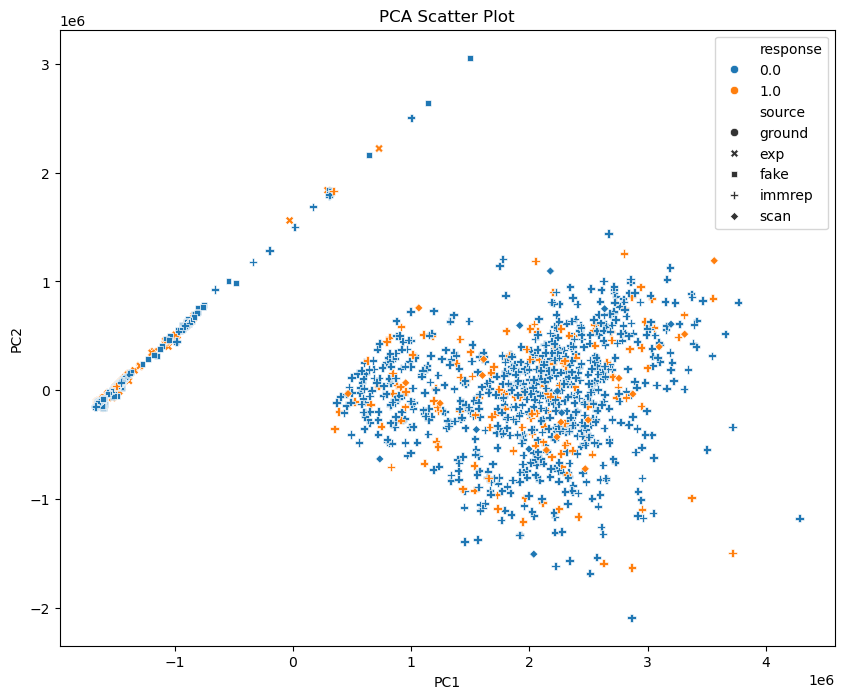

In [27]:
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#Next we want to determine which features are most affected by batch effect using principal loading analysis
features = pd.read_csv("../data/Features/features.csv")
cls_data = pd.read_csv("../data/ML/Annotation.csv")

#how many feature columns have na
print(features.shape)
na_counts = features.isna().sum()
print(len(na_counts[na_counts > 0]))

#Let's first create function to just look at the PCA and color by response variable (binding) and use shape for the batches
def plot_PCA(features,cls):
    pca = PCA(n_components=50)
    #pass everything but the index column and get rid of columns with missing values
    names = features["name"]
    components = pca.fit_transform(features.drop(columns=["name"]).dropna(axis=1))
    pca_df = pd.DataFrame(components[:, :2], columns=['PC1', 'PC2'])
    pca_df = pd.concat([pca_df, cls[cls["name"].isin(names)].reset_index(drop=True)], axis=1)
    return pca_df

def plot_PCA_scatter(pca_df, color_col, shape_col):
    plt.figure(figsize=(10, 8))
    sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue=color_col, style=shape_col)
    plt.title('PCA Scatter Plot')
    plt.show()


pca_df = plot_PCA(features, cls_data)
# cls_data.head()
plot_PCA_scatter(pca_df, color_col='response', shape_col='source')

In [ ]:
sns.Scatter_Density(data = sponge.pca.before$variates$X, batch = sponge.batch, 
                trt = sponge.trt, expl.var = sponge.pca.before$explained_variance, 
                xlim = c(-4.5,5), ylim = c(-3,4), 
                batch.legend.title = 'Gel (batch)', 
                trt.legend.title = 'Tissue (trt)', 
                title = 'Before batch effect correction (Sponge)')

In [44]:
print(cls_data.head())
print(features.head())

    name  response  source       Allele species    Peptide        TRAV  \
1   1ao7         1  ground  HLA-A*02:01   Human  LLFGYPVYV    TRAV12-2   
2   1bd2         1  ground  HLA-A*02:01   Human  LLFGYPVYV  TRAV29/DV5   
6   1lp9         1  ground  HLA-A*02:01   Human  ALWGFFPVL   TRAV12D-2   
7   1mi5         1  ground  HLA-B*08:01   Human  FLRGRAYGL    TRAV26-2   
10  1oga         1  ground  HLA-A*02:01   Human  GILGFVFTL      TRAV27   

        TRBV   Type  
1    TRBV6-5  HLA-A  
2    TRBV6-5  HLA-A  
6   TRBV13-3  HLA-A  
7    TRBV7-8  HLA-B  
10    TRBV19  HLA-A  
   name  MHC_class  Total:Num_Residues  Total:Num_hydrophobic  \
0  1ao7          1                 411                    183   
1  1bd2          1                 408                    184   
2  1d9k          2                 409                    173   
3  1fo0          1                 415                    182   
4  1fyt          2                 411                    179   

   Total:Num_polar  Total:Num_ac

In [47]:
#Now we want to determine which features drive any effect different from the response column
#To do this we will calculate the average value of each feature split by the columns of the cls data
#We will then calculate the average variance between these averages and output the normalized average variance of each feature as columns of a dataframe with rows being the columns of the cls data
# print(features.head())
import numpy as np
def findBiasedFeatures(features, cls):
    #drop any feature column that is not numeric
    features = features.select_dtypes(include=[np.number])
    cls_columns = cls.columns
    features_columns = features.columns
    print(cls_columns)
    print(features_columns)
    biased_features = pd.DataFrame(index=cls_columns, columns=features_columns)
    for col in cls.columns:
        if col == "name":
            continue
        grouped = features.groupby(cls[col])  # Group features by the current column in cls
        avg_values = grouped.mean()  # Calculate the average value of each feature for each group
        avg_variance = avg_values.var(axis=0)  # Calculate the variance between these averages
        biased_features.loc[col] = avg_variance / avg_variance.sum()
    return biased_features
biased_features = findBiasedFeatures(features, cls_data)
biased_features

Index(['name', 'response', 'source', 'Allele', 'species', 'Peptide', 'TRAV',
       'TRBV', 'Type'],
      dtype='object')
Index(['MHC_class', 'Total:Num_Residues', 'Total:Num_hydrophobic',
       'Total:Num_polar', 'Total:Num_acidic', 'Total:Num_basic',
       'Total:Num_negative', 'Total:Num_positive', 'Total:Num_aromatic',
       'Total:Num_aliphatic',
       ...
       'volume:TCRcb:structure_volume', 'volume:TCRcb:fill', 'clashes:TCRca',
       'clashes:TCRcb', 'energy:region_energy:TCRca:bound',
       'energy:region_energy:TCRca:unbound',
       'energy:region_energy:TCRca:difference',
       'energy:region_energy:TCRcb:bound',
       'energy:region_energy:TCRcb:unbound',
       'energy:region_energy:TCRcb:difference'],
      dtype='object', length=714)


,MHC_class,Total:Num_Residues,Total:Num_hydrophobic,Total:Num_polar,Total:Num_acidic,Total:Num_basic,Total:Num_negative,Total:Num_positive,Total:Num_aromatic,Total:Num_aliphatic,...,volume:TCRcb:structure_volume,volume:TCRcb:fill,clashes:TCRca,clashes:TCRcb,energy:region_energy:TCRca:bound,energy:region_energy:TCRca:unbound,energy:region_energy:TCRca:difference,energy:region_energy:TCRcb:bound,energy:region_energy:TCRcb:unbound,energy:region_energy:TCRcb:difference
name,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
response,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
source,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000031,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Allele,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000051,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
species,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Peptide,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000041,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
TRAV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
TRBV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000027,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Type,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


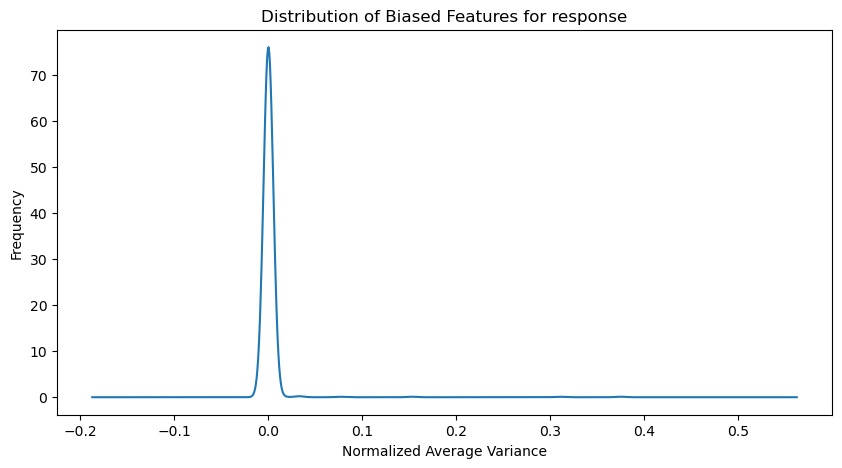

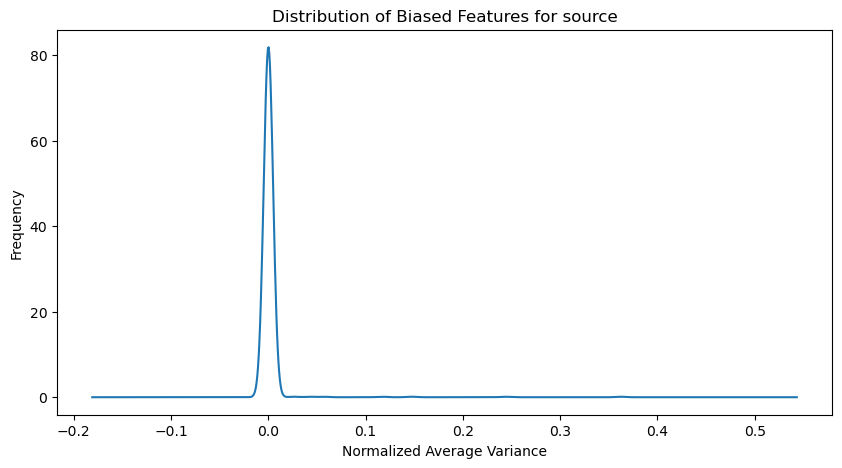

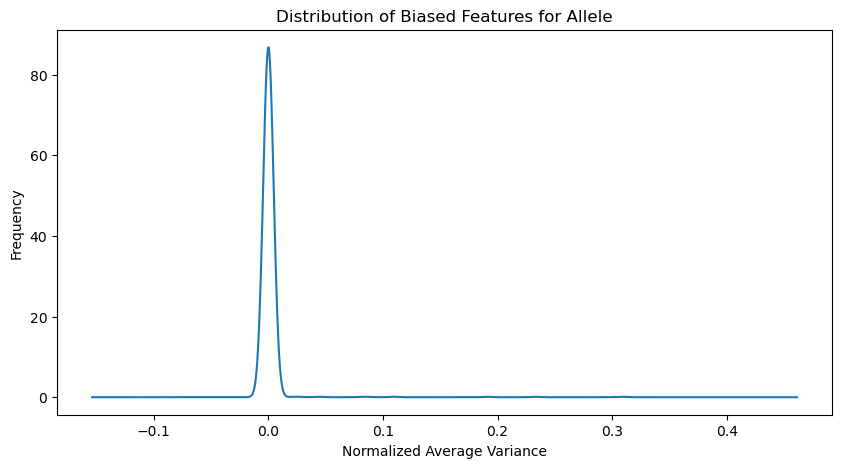

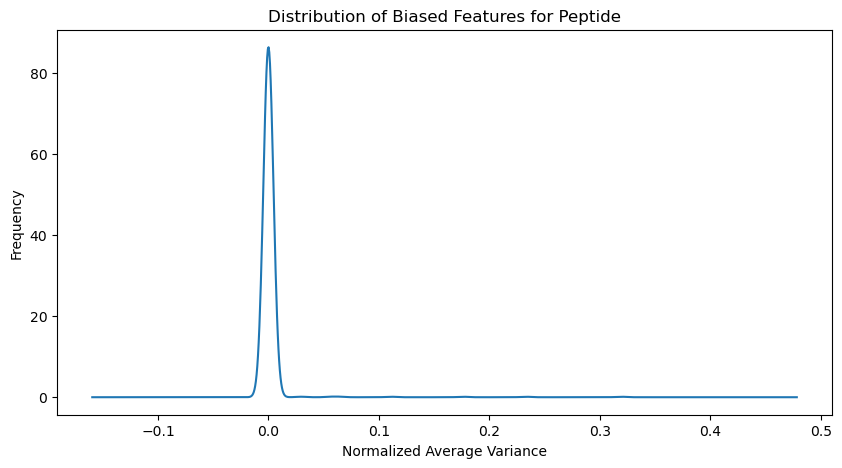

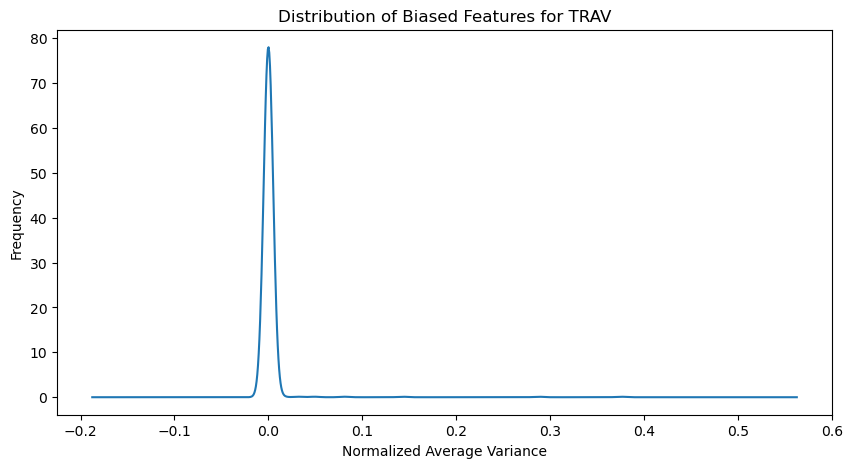

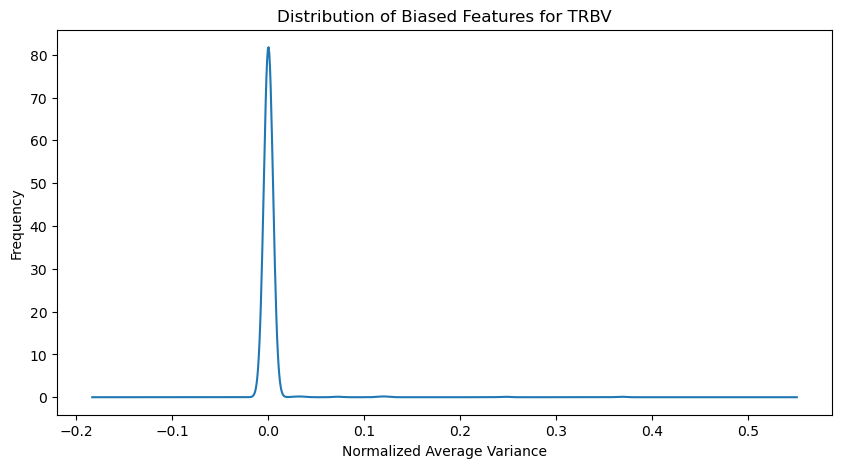

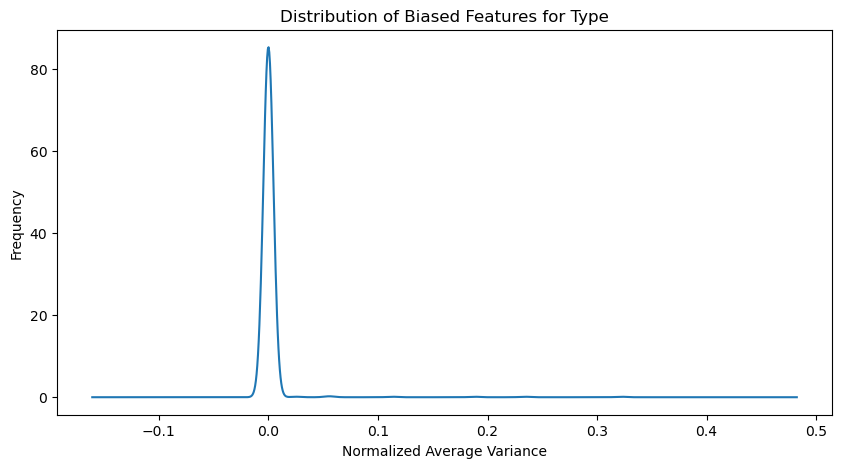

In [ ]:
#remove the name and species rows from the biased_features
biased_features = biased_features.drop(index=["name", "species"], errors="ignore")
#Plot a distribution of each row of the biased_features as a density plot   
for col in biased_features.index:
    plt.figure(figsize=(10, 5))
    biased_features.loc[col].plot(kind='density')
    plt.title(f"Distribution of Biased Features for {col}")
    plt.xlabel("Normalized Average Variance")
    plt.ylabel("Frequency")
    plt.show()


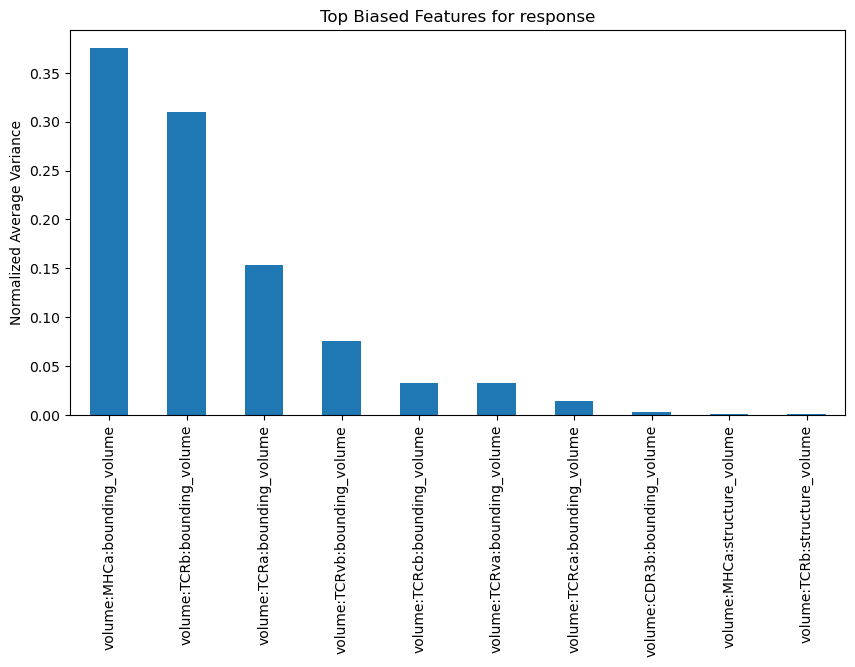

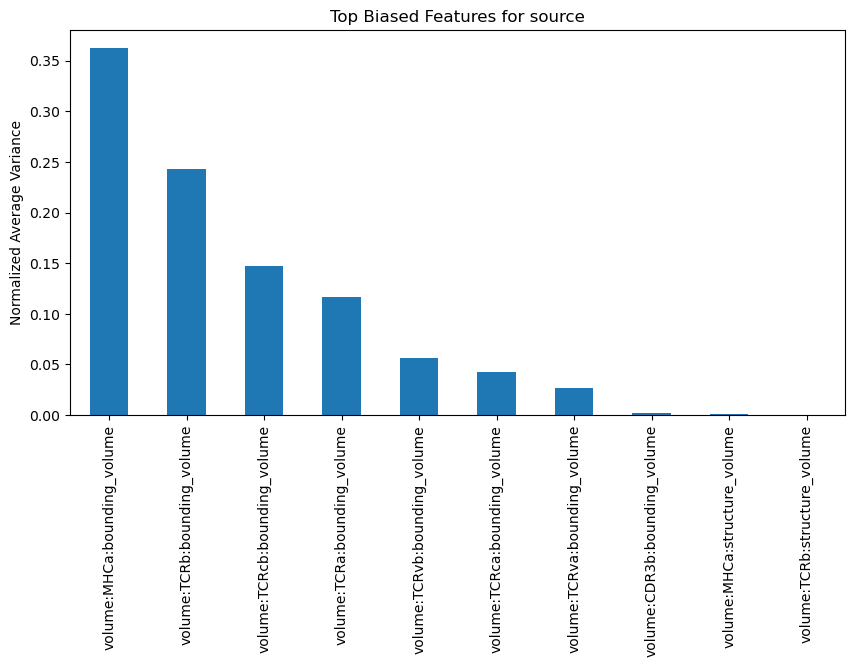

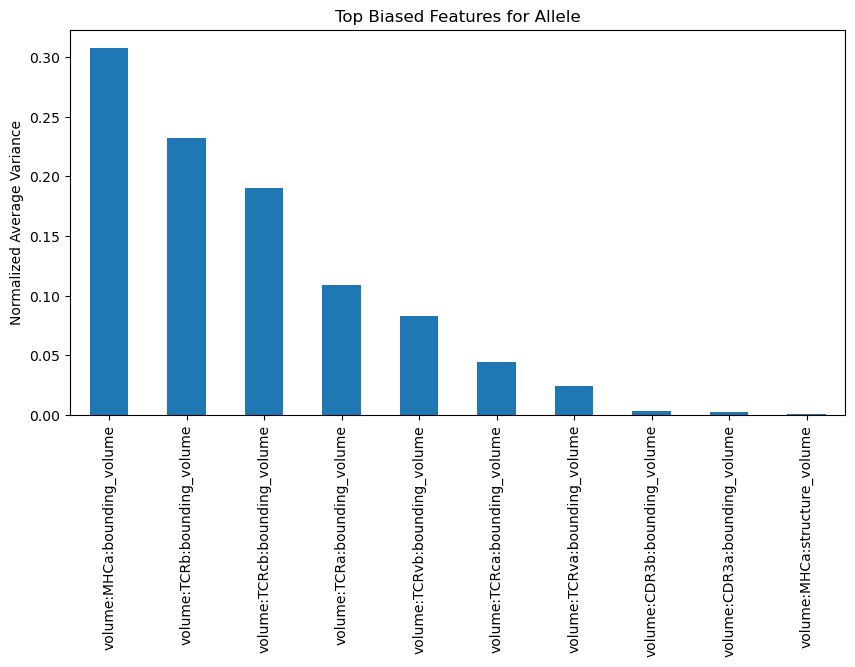

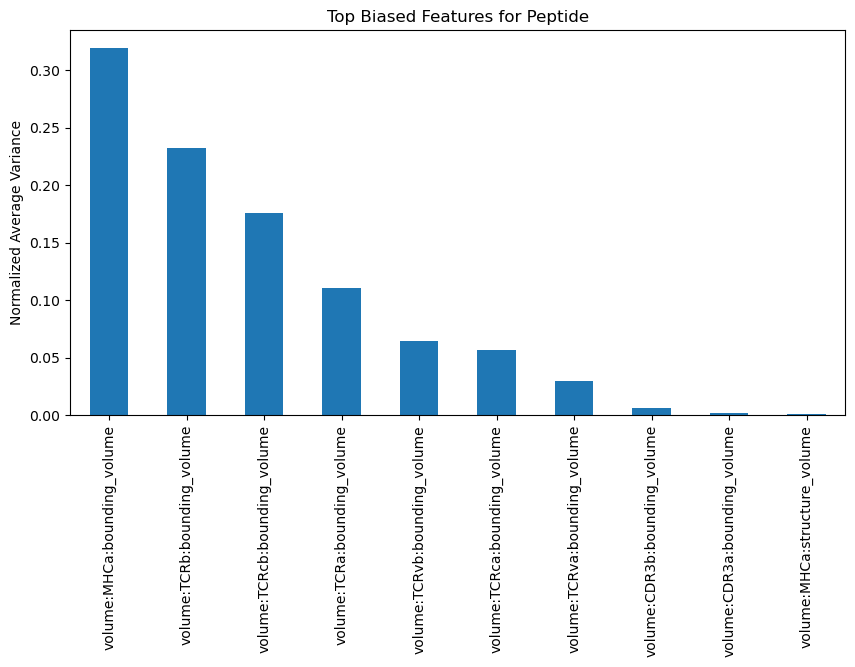

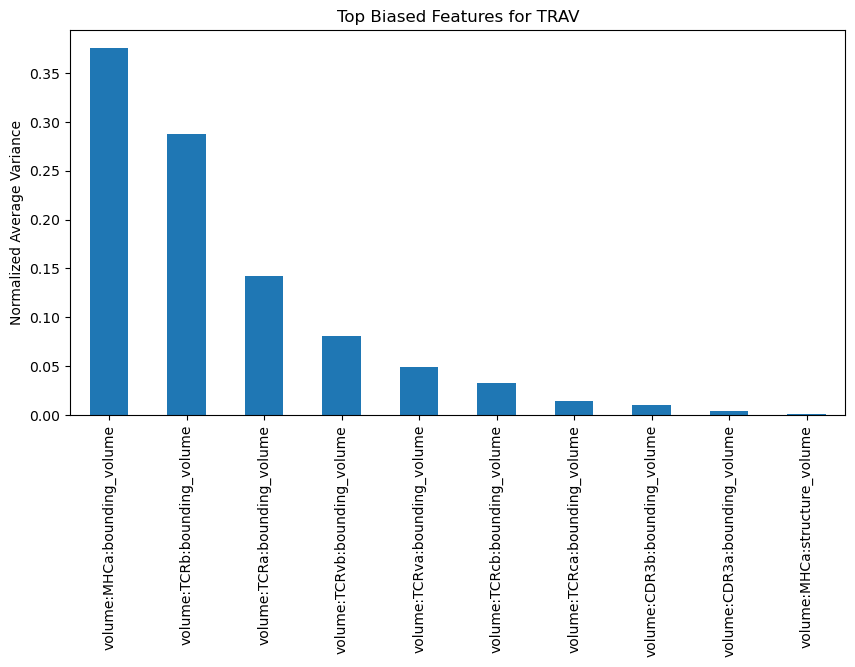

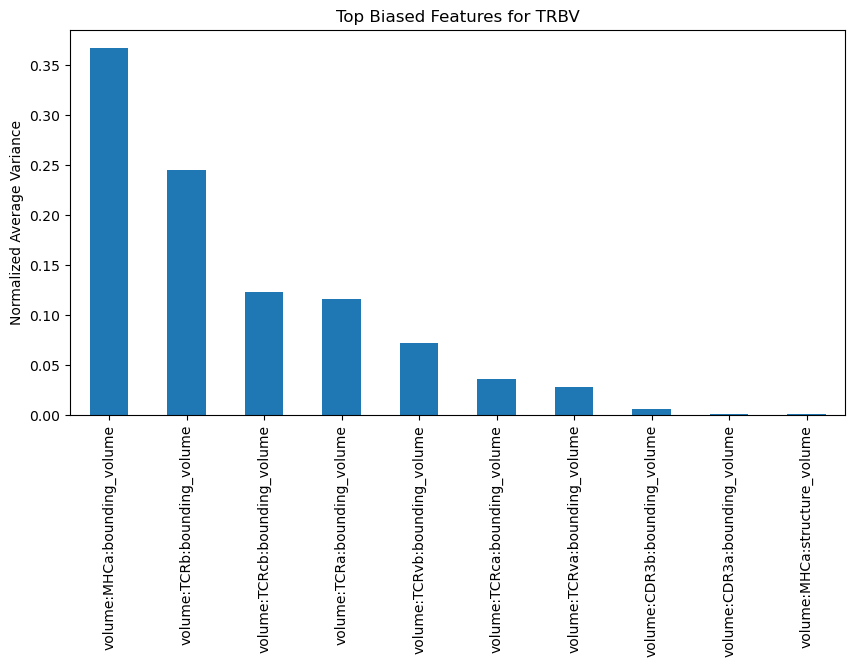

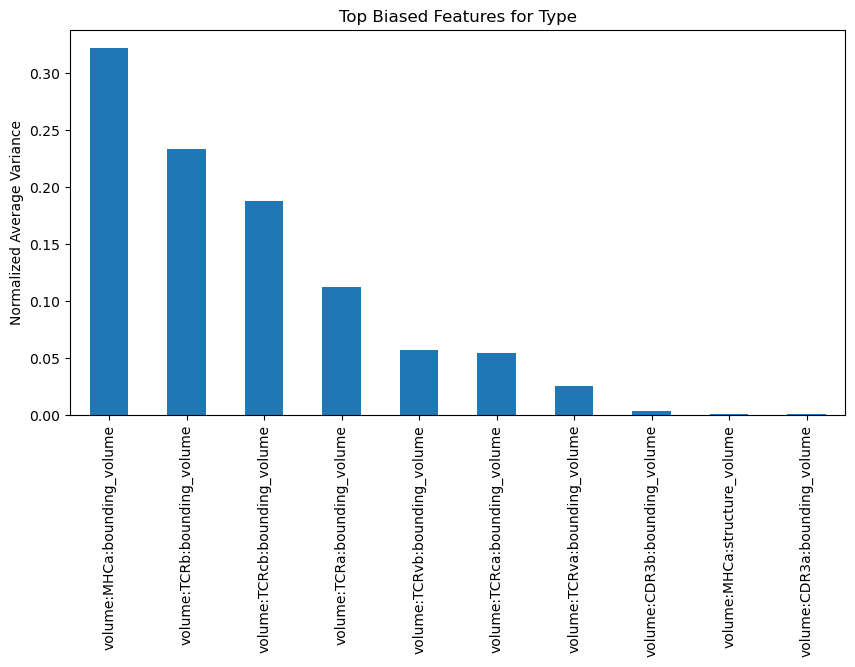

In [55]:
#Now create a visualization to show the top biased features for each column in the cls data
import matplotlib.pyplot as plt
for col in biased_features.index:
    top_features = biased_features.loc[col].sort_values(ascending=False).head(10)
    plt.figure(figsize=(10, 5))
    top_features.plot(kind='bar')
    plt.title(f"Top Biased Features for {col}")
    plt.ylabel("Normalized Average Variance")
    plt.show()